# Факторный анализ в Python

**Дисциплина:** Введение в анализ больших данных

**Факторный анализ** снижает размерность: много наблюдаемых переменных объясняются меньшим числом **латентных факторов**.

- **нагрузки (loadings)** — связь переменных с факторами;
- **общность (communality)** — доля дисперсии, объяснённая факторами;
- **собственные значения** — вклад факторов;
- **вращение (varimax)** — для интерпретируемости.

Инструменты: `sklearn.decomposition.FactorAnalysis`, собственные значения / scree, varimax.

Демо: синтетический опрос о качестве сервиса.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(7)


---
## 1. Данные

Девять пунктов шкалы 1–5. Заложены три латентных фактора:  
«качество», «доставка», «поддержка».


In [11]:
n = 120
Q = np.random.normal(0, 1, n)
D = np.random.normal(0, 1, n)
S = np.random.normal(0, 1, n)

items = pd.DataFrame({
    "product_quality": 0.80*Q + 0.10*D + np.random.normal(0, 0.35, n),
    "packaging":       0.70*Q + 0.15*D + np.random.normal(0, 0.40, n),
    "value_for_money": 0.65*Q + 0.20*S + np.random.normal(0, 0.45, n),
    "delivery_speed":  0.15*Q + 0.80*D + np.random.normal(0, 0.35, n),
    "tracking":        0.10*Q + 0.75*D + np.random.normal(0, 0.40, n),
    "pack_condition":  0.20*Q + 0.70*D + np.random.normal(0, 0.40, n),
    "response_time":   0.10*D + 0.80*S + np.random.normal(0, 0.35, n),
    "staff_politeness":0.15*Q + 0.75*S + np.random.normal(0, 0.40, n),
    "issue_resolve":   0.85*S + np.random.normal(0, 0.40, n),
})
items = (3.2 + items).clip(1, 5)
print(items.describe().round(2).T[["mean", "std", "min", "max"]])


                  mean   std   min   max
product_quality   3.16  0.90  1.10  5.00
packaging         3.21  0.79  1.50  5.00
value_for_money   3.19  0.78  1.37  4.87
delivery_speed    3.09  0.81  1.04  4.99
tracking          3.18  0.83  1.31  4.95
pack_condition    3.16  0.75  1.40  5.00
response_time     3.12  0.91  1.00  5.00
staff_politeness  3.16  0.85  1.02  5.00
issue_resolve     3.11  0.95  1.00  5.00


### Корреляционная матрица


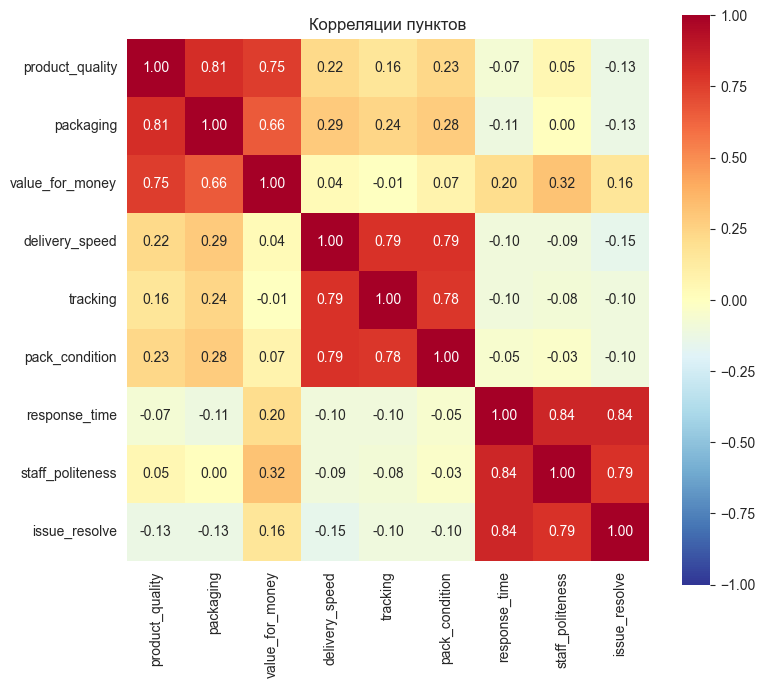

In [3]:
corr = items.corr()
plt.figure(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Корреляции пунктов")
plt.tight_layout()
plt.show()


---
## 2. Число факторов: scree и parallel analysis

Критерий Кайзера: собственные значения > 1.  
Parallel analysis: сравниваем с собственными значениями случайных данных.


Собственные значения: [3.144 2.739 1.937 0.273 0.225 0.205 0.187 0.158 0.132]


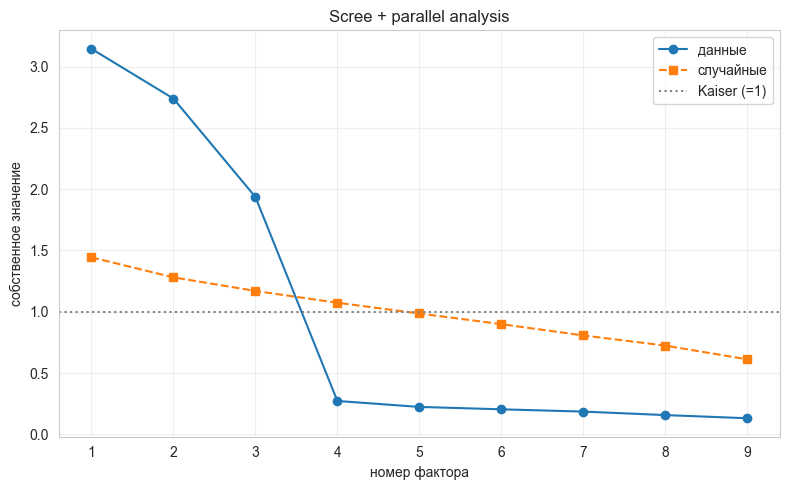

По parallel analysis (eig > random): 3


In [4]:
eigvals = np.linalg.eigvalsh(corr.values)[::-1]
print("Собственные значения:", np.round(eigvals, 3))

n_perm = 40
rand_eigs = []
for _ in range(n_perm):
    R = StandardScaler().fit_transform(np.random.normal(size=items.shape))
    C = np.corrcoef(R.T)
    rand_eigs.append(np.linalg.eigvalsh(C)[::-1])
rand_eigs = np.mean(rand_eigs, axis=0)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigvals)+1), eigvals, "o-", label="данные")
plt.plot(range(1, len(rand_eigs)+1), rand_eigs, "s--", label="случайные")
plt.axhline(1, color="gray", ls=":", label="Kaiser (=1)")
plt.xlabel("номер фактора")
plt.ylabel("собственное значение")
plt.title("Scree + parallel analysis")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("По parallel analysis (eig > random):", int(np.sum(eigvals > rand_eigs)))


---
## 3. Оценка факторной модели

`FactorAnalysis` + вращение **varimax**.


In [5]:
def varimax(Phi, gamma=1.0, q=30, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0.0
    for _ in range(q):
        d_old = d
        Lambda = Phi @ R
        u, s, vh = np.linalg.svd(
            Phi.T @ (Lambda**3 - (gamma / p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda)))
        )
        R = u @ vh
        d = float(np.sum(s))
        if d_old and d / d_old < 1 + tol:
            break
    return Phi @ R

def fit_fa(data, n_factors):
    fa = FactorAnalysis(n_components=n_factors, random_state=0, max_iter=2000)
    fa.fit(data)
    loadings = varimax(fa.components_.T)
    df = pd.DataFrame(
        loadings, index=data.columns,
        columns=[f"F{i+1}" for i in range(n_factors)],
    )
    df["communality"] = (loadings ** 2).sum(axis=1)
    return df, fa


In [6]:
print("=== 2 фактора ===")
load2, _ = fit_fa(items, 2)
print(load2.round(3))

print("\n=== 3 фактора ===")
load3, _ = fit_fa(items, 3)
print(load3.round(3))


=== 2 фактора ===
                     F1     F2  communality
product_quality   0.051  0.845        0.717
packaging         0.074  0.674        0.459
value_for_money  -0.192  0.621        0.423
delivery_speed    0.112  0.203        0.054
tracking          0.101  0.159        0.036
pack_condition    0.063  0.195        0.042
response_time    -0.847 -0.020        0.718
staff_politeness -0.765  0.094        0.594
issue_resolve    -0.848 -0.073        0.725

=== 3 фактора ===
                     F1     F2     F3  communality
product_quality   0.053  0.838  0.098        0.715
packaging         0.071  0.657  0.152        0.460
value_for_money  -0.184  0.641 -0.038        0.447
delivery_speed    0.068  0.102  0.715        0.527
tracking          0.055  0.053  0.728        0.536
pack_condition    0.020  0.105  0.648        0.431
response_time    -0.850 -0.017 -0.023        0.723
staff_politeness -0.763  0.099 -0.030        0.593
issue_resolve    -0.846 -0.064 -0.064        0.723


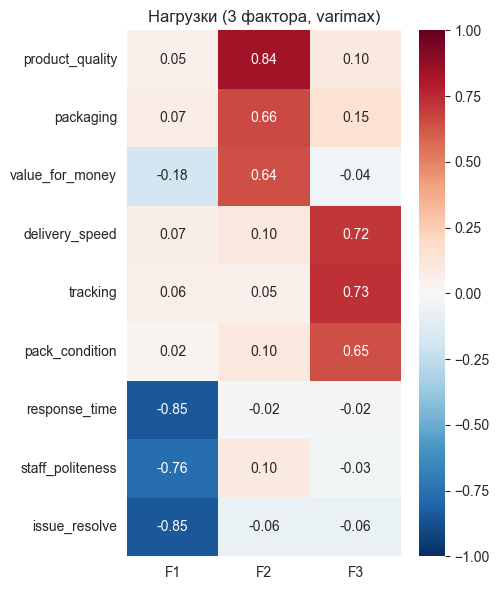

In [7]:
plt.figure(figsize=(5, 6))
sns.heatmap(load3.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Нагрузки (3 фактора, varimax)")
plt.tight_layout()
plt.show()


### Как читать нагрузки

- |нагрузка| ≳ 0.4–0.5 → переменная связана с фактором;  
- высокая **communality** → пункт хорошо объясняется факторами;  
- дайте факторам **содержательные** имена по сильным нагрузкам.


---
## 4. KMO (пригодность данных для FA)

Желательно KMO > 0.6.


In [8]:
def kmo_simple(corr):
    C = np.asarray(corr, float).copy()
    inv = np.linalg.inv(C)
    pcorr = -inv / np.sqrt(np.outer(np.diag(inv), np.diag(inv)))
    np.fill_diagonal(pcorr, 0)
    np.fill_diagonal(C, 0)
    r2 = (C ** 2).sum()
    p2 = (pcorr ** 2).sum()
    return r2 / (r2 + p2)

print(f"KMO ≈ {kmo_simple(corr.values):.3f}")


KMO ≈ 0.761


### Как описать результаты

1. Корреляции и KMO — уместен ли FA.  
2. Scree / parallel — сколько факторов.  
3. Таблица нагрузок после varimax — интерпретация и имена факторов.  
4. Communality — насколько хорошо каждый пункт объясняется.

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Корреляции | `df.corr()` |
| Собственные значения | `np.linalg.eigvalsh(corr)[::-1]` |
| FA | `FactorAnalysis(n_components=k).fit(X)` |
| Нагрузки | `fa.components_.T` (+ varimax) |
| Communality | `(loadings**2).sum(axis=1)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните FA **самостоятельно** на своём CSV.  
2. Число факторов выбирайте и по числам, и по интерпретируемости.

Удачи!


In [12]:
import os
from google.colab import files

print("Доступные файлы в рабочей директории:")
print(os.listdir())

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
    data = pd.read_csv(file_name)
elif file_name.endswith('.xlsx'):
    data = pd.read_excel(file_name)
else:
    raise ValueError("Формат файла не поддерживается. Используйте CSV или Excel.")

print(f"\nФайл '{file_name}' успешно загружен!")
data.to_excel('data.xlsx')

ModuleNotFoundError: No module named 'google.colab'